In [ ]:
# Instalação do PySpark
!pip install pyspark

In [ ]:
# Importação das bibliotecas necessárias

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.ml import Pipeline
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler)
from pyspark.ml.classification import (LogisticRegression, DecisionTreeClassifier, RandomForestClassifier)
from pyspark.ml.evaluation import (MulticlassClassificationEvaluator, BinaryClassificationEvaluator)

In [ ]:
# Criação da sessão Spark
spark = SparkSession.builder.getOrCreate()

In [ ]:
# Configuração para melhorar a visualização dos gráficos
sns.set_theme(style="whitegrid")

# Exibir todas as colunas dos DataFrames
pd.set_option('display.max_columns', None)

In [ ]:
# Importar a biblioteca para acessar o Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Carregar o arquivo
df = spark.read.csv('/content/drive/MyDrive/Projeto Semantix/data/default_of_credit_card_clients.csv', header=False, inferSchema=True)

In [ ]:
# Visualização dos primeiros registros
df.show(5)

+----+---------+---+---------+--------+---+-----+-----+-----+-----+-----+-----+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+--------------------+
| _c0|      _c1|_c2|      _c3|     _c4|_c5|  _c6|  _c7|  _c8|  _c9| _c10| _c11|     _c12|     _c13|     _c14|     _c15|     _c16|     _c17|    _c18|    _c19|    _c20|    _c21|    _c22|    _c23|                _c24|
+----+---------+---+---------+--------+---+-----+-----+-----+-----+-----+-----+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+--------------------+
|NULL|       X1| X2|       X3|      X4| X5|   X6|   X7|   X8|   X9|  X10|  X11|      X12|      X13|      X14|      X15|      X16|      X17|     X18|     X19|     X20|     X21|     X22|     X23|                   Y|
|  ID|LIMIT_BAL|SEX|EDUCATION|MARRIAGE|AGE|PAY_0|PAY_2|PAY_3|PAY_4|PAY_5|PAY_6|BILL_AMT1|BILL_AMT2|BILL_AMT3|BILL_AMT4|BILL_AMT5|BILL_AMT6|P

In [ ]:
# Remover a primeira linha (cabeçalho extra)
df = df.filter(df["_c0"] != "NULL")

# Utilizar a primeira linha restante como cabeçalho
cabecalho = df.first()

# Renomear as colunas
novos_nomes = cabecalho

df = df.filter(df["_c0"] != "ID")

df = df.toDF(
    "ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4",
    "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4",
    "PAY_AMT5", "PAY_AMT6",
    "default_payment_next_month"
)

In [ ]:
df.show(3)

+---+---------+---+---------+--------+---+-----+-----+-----+-----+-----+-----+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+--------------------------+
| ID|LIMIT_BAL|SEX|EDUCATION|MARRIAGE|AGE|PAY_0|PAY_2|PAY_3|PAY_4|PAY_5|PAY_6|BILL_AMT1|BILL_AMT2|BILL_AMT3|BILL_AMT4|BILL_AMT5|BILL_AMT6|PAY_AMT1|PAY_AMT2|PAY_AMT3|PAY_AMT4|PAY_AMT5|PAY_AMT6|default_payment_next_month|
+---+---------+---+---------+--------+---+-----+-----+-----+-----+-----+-----+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+--------------------------+
|  1|    20000|  2|        2|       1| 24|    2|    2|   -1|   -1|   -2|   -2|     3913|     3102|      689|        0|        0|        0|       0|     689|       0|       0|       0|       0|                         1|
|  2|   120000|  2|        2|       2| 26|   -1|    2|    0|    0|    0|    2|     2682|     1725|     2682|     3272|  

In [ ]:
# Quantidade de registros
print("Total de registros:", df.count())

# Quantidade de colunas
print("Total de colunas:", len(df.columns))

# Nome das colunas
print("Colunas:", df.columns)

# Tipos de dados
df.printSchema()

Total de registros: 30000
Total de colunas: 25
Colunas: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default_payment_next_month']
root
 |-- ID: string (nullable = true)
 |-- LIMIT_BAL: string (nullable = true)
 |-- SEX: string (nullable = true)
 |-- EDUCATION: string (nullable = true)
 |-- MARRIAGE: string (nullable = true)
 |-- AGE: string (nullable = true)
 |-- PAY_0: string (nullable = true)
 |-- PAY_2: string (nullable = true)
 |-- PAY_3: string (nullable = true)
 |-- PAY_4: string (nullable = true)
 |-- PAY_5: string (nullable = true)
 |-- PAY_6: string (nullable = true)
 |-- BILL_AMT1: string (nullable = true)
 |-- BILL_AMT2: string (nullable = true)
 |-- BILL_AMT3: string (nullable = true)
 |-- BILL_AMT4: string (nullable = true)
 |-- BILL_AMT5: string (nullable =

In [ ]:
# Contar valores nulos em cada coluna
df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c)for c in df.columns]).show(vertical=True)

-RECORD 0-------------------------
 ID                         | 0   
 LIMIT_BAL                  | 0   
 SEX                        | 0   
 EDUCATION                  | 0   
 MARRIAGE                   | 0   
 AGE                        | 0   
 PAY_0                      | 0   
 PAY_2                      | 0   
 PAY_3                      | 0   
 PAY_4                      | 0   
 PAY_5                      | 0   
 PAY_6                      | 0   
 BILL_AMT1                  | 0   
 BILL_AMT2                  | 0   
 BILL_AMT3                  | 0   
 BILL_AMT4                  | 0   
 BILL_AMT5                  | 0   
 BILL_AMT6                  | 0   
 PAY_AMT1                   | 0   
 PAY_AMT2                   | 0   
 PAY_AMT3                   | 0   
 PAY_AMT4                   | 0   
 PAY_AMT5                   | 0   
 PAY_AMT6                   | 0   
 default_payment_next_month | 0   



In [ ]:
# Contar registros totais
total_registros = df.count()

# Contar registros sem duplicatas
registros_unicos = df.dropDuplicates().count()

# Calcular duplicatas
duplicados = total_registros - registros_unicos

print("Total de registros:", total_registros)
print("Registros únicos:", registros_unicos)
print("Registros duplicados:", duplicados)

Total de registros: 30000
Registros únicos: 30000
Registros duplicados: 0


In [ ]:
# Estatísticas descritivas
df.describe().show(truncate=False)

+-------+-----------------+------------------+------------------+------------------+------------------+-----------------+------------------+--------------------+------------------+--------------------+------------------+-----------------+-----------------+-----------------+-----------------+------------------+-----------------+----------------+-----------------+------------------+-----------------+------------------+------------------+-----------------+--------------------------+
|summary|ID               |LIMIT_BAL         |SEX               |EDUCATION         |MARRIAGE          |AGE              |PAY_0             |PAY_2               |PAY_3             |PAY_4               |PAY_5             |PAY_6            |BILL_AMT1        |BILL_AMT2        |BILL_AMT3        |BILL_AMT4         |BILL_AMT5        |BILL_AMT6       |PAY_AMT1         |PAY_AMT2          |PAY_AMT3         |PAY_AMT4          |PAY_AMT5          |PAY_AMT6         |default_payment_next_month|
+-------+-----------------+---

In [ ]:
# Distribuição da variável-alvo (A interpretação é  0: cliente não apresentou inadimplência / 1: cliente apresentou inadimplência)
df.groupBy("default_payment_next_month").count().orderBy("default_payment_next_month").show()

+--------------------------+-----+
|default_payment_next_month|count|
+--------------------------+-----+
|                         0|23364|
|                         1| 6636|
+--------------------------+-----+



In [ ]:
# Conferir os maiores valores de algumas variáveis
df.select(
    "ID",
    "LIMIT_BAL",
    "BILL_AMT1",
    "PAY_AMT1",
    "PAY_AMT6"
).orderBy(
    F.col("LIMIT_BAL").desc()
).show(10, truncate=False)

+---+---------+---------+--------+--------+
|ID |LIMIT_BAL|BILL_AMT1|PAY_AMT1|PAY_AMT6|
+---+---------+---------+--------+--------+
|351|90000    |39128    |1541    |3000    |
|625|90000    |491      |0       |0       |
|373|90000    |34302    |1640    |2000    |
|25 |90000    |4744     |5757    |2000    |
|431|90000    |91894    |3200    |3100    |
|169|90000    |72112    |3500    |0       |
|470|90000    |6160     |3276    |1362    |
|502|90000    |23132    |0       |2000    |
|623|90000    |7624     |0       |0       |
|567|90000    |13141    |1600    |764     |
+---+---------+---------+--------+--------+
only showing top 10 rows


In [ ]:
# Converter todas as colunas para números inteiros
for coluna in df.columns:df = df.withColumn(coluna,col(coluna).cast("long"))

# Conferir os tipos de dados
df.printSchema()

root
 |-- ID: long (nullable = true)
 |-- LIMIT_BAL: long (nullable = true)
 |-- SEX: long (nullable = true)
 |-- EDUCATION: long (nullable = true)
 |-- MARRIAGE: long (nullable = true)
 |-- AGE: long (nullable = true)
 |-- PAY_0: long (nullable = true)
 |-- PAY_2: long (nullable = true)
 |-- PAY_3: long (nullable = true)
 |-- PAY_4: long (nullable = true)
 |-- PAY_5: long (nullable = true)
 |-- PAY_6: long (nullable = true)
 |-- BILL_AMT1: long (nullable = true)
 |-- BILL_AMT2: long (nullable = true)
 |-- BILL_AMT3: long (nullable = true)
 |-- BILL_AMT4: long (nullable = true)
 |-- BILL_AMT5: long (nullable = true)
 |-- BILL_AMT6: long (nullable = true)
 |-- PAY_AMT1: long (nullable = true)
 |-- PAY_AMT2: long (nullable = true)
 |-- PAY_AMT3: long (nullable = true)
 |-- PAY_AMT4: long (nullable = true)
 |-- PAY_AMT5: long (nullable = true)
 |-- PAY_AMT6: long (nullable = true)
 |-- default_payment_next_month: long (nullable = true)



In [ ]:
# Contar valores nulos após a conversão
df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c)for c in df.columns]).show(vertical=True)

-RECORD 0-------------------------
 ID                         | 0   
 LIMIT_BAL                  | 0   
 SEX                        | 0   
 EDUCATION                  | 0   
 MARRIAGE                   | 0   
 AGE                        | 0   
 PAY_0                      | 0   
 PAY_2                      | 0   
 PAY_3                      | 0   
 PAY_4                      | 0   
 PAY_5                      | 0   
 PAY_6                      | 0   
 BILL_AMT1                  | 0   
 BILL_AMT2                  | 0   
 BILL_AMT3                  | 0   
 BILL_AMT4                  | 0   
 BILL_AMT5                  | 0   
 BILL_AMT6                  | 0   
 PAY_AMT1                   | 0   
 PAY_AMT2                   | 0   
 PAY_AMT3                   | 0   
 PAY_AMT4                   | 0   
 PAY_AMT5                   | 0   
 PAY_AMT6                   | 0   
 default_payment_next_month | 0   



In [ ]:
# Estatísticas descritivas após a conversão dos valores
df.describe().show(truncate=False)

+-------+-----------------+------------------+------------------+------------------+------------------+-----------------+------------------+--------------------+------------------+--------------------+------------------+-----------------+-----------------+-----------------+-----------------+------------------+-----------------+----------------+-----------------+------------------+-----------------+------------------+------------------+-----------------+--------------------------+
|summary|ID               |LIMIT_BAL         |SEX               |EDUCATION         |MARRIAGE          |AGE              |PAY_0             |PAY_2               |PAY_3             |PAY_4               |PAY_5             |PAY_6            |BILL_AMT1        |BILL_AMT2        |BILL_AMT3        |BILL_AMT4         |BILL_AMT5        |BILL_AMT6       |PAY_AMT1         |PAY_AMT2          |PAY_AMT3         |PAY_AMT4          |PAY_AMT5          |PAY_AMT6         |default_payment_next_month|
+-------+-----------------+---

In [ ]:
# Distribuição das variáveis categóricas

variaveis = ["SEX", "EDUCATION", "MARRIAGE"]

for coluna in variaveis:
    print(f"\nDistribuição da variável: {coluna}")

    df.groupBy(coluna).count().orderBy(coluna).show()


Distribuição da variável: SEX
+---+-----+
|SEX|count|
+---+-----+
|  1|11888|
|  2|18112|
+---+-----+


Distribuição da variável: EDUCATION
+---------+-----+
|EDUCATION|count|
+---------+-----+
|        0|   14|
|        1|10585|
|        2|14030|
|        3| 4917|
|        4|  123|
|        5|  280|
|        6|   51|
+---------+-----+


Distribuição da variável: MARRIAGE
+--------+-----+
|MARRIAGE|count|
+--------+-----+
|       0|   54|
|       1|13659|
|       2|15964|
|       3|  323|
+--------+-----+



In [ ]:
# Escolaridade, sexo e estado civil versus inadimplência
variaveis = ["SEX", "EDUCATION", "MARRIAGE"]

for coluna in variaveis:
    print(f"\nInadimplência por {coluna}")

    df.groupBy(coluna).agg(
        F.count("*").alias("total_clientes"),
        F.sum("default_payment_next_month").alias("inadimplentes"),
        F.round(
            F.avg("default_payment_next_month") * 100, 2
        ).alias("taxa_inadimplencia")
    ).orderBy(coluna).show()


Inadimplência por SEX
+---+--------------+-------------+------------------+
|SEX|total_clientes|inadimplentes|taxa_inadimplencia|
+---+--------------+-------------+------------------+
|  1|         11888|         2873|             24.17|
|  2|         18112|         3763|             20.78|
+---+--------------+-------------+------------------+


Inadimplência por EDUCATION
+---------+--------------+-------------+------------------+
|EDUCATION|total_clientes|inadimplentes|taxa_inadimplencia|
+---------+--------------+-------------+------------------+
|        0|            14|            0|               0.0|
|        1|         10585|         2036|             19.23|
|        2|         14030|         3330|             23.73|
|        3|          4917|         1237|             25.16|
|        4|           123|            7|              5.69|
|        5|           280|           18|              6.43|
|        6|            51|            8|             15.69|
+---------+------------

In [ ]:
# Variáveis de histórico de pagamento
variaveis_pay = ["PAY_0", "PAY_2", "PAY_3","PAY_4", "PAY_5", "PAY_6"]

for coluna in variaveis_pay:
    print(f"\nDistribuição da variável: {coluna}")

    df.groupBy(coluna).count().orderBy(coluna).show()


Distribuição da variável: PAY_0
+-----+-----+
|PAY_0|count|
+-----+-----+
|   -2| 2759|
|   -1| 5686|
|    0|14737|
|    1| 3688|
|    2| 2667|
|    3|  322|
|    4|   76|
|    5|   26|
|    6|   11|
|    7|    9|
|    8|   19|
+-----+-----+


Distribuição da variável: PAY_2
+-----+-----+
|PAY_2|count|
+-----+-----+
|   -2| 3782|
|   -1| 6050|
|    0|15730|
|    1|   28|
|    2| 3927|
|    3|  326|
|    4|   99|
|    5|   25|
|    6|   12|
|    7|   20|
|    8|    1|
+-----+-----+


Distribuição da variável: PAY_3
+-----+-----+
|PAY_3|count|
+-----+-----+
|   -2| 4085|
|   -1| 5938|
|    0|15764|
|    1|    4|
|    2| 3819|
|    3|  240|
|    4|   76|
|    5|   21|
|    6|   23|
|    7|   27|
|    8|    3|
+-----+-----+


Distribuição da variável: PAY_4
+-----+-----+
|PAY_4|count|
+-----+-----+
|   -2| 4348|
|   -1| 5687|
|    0|16455|
|    1|    2|
|    2| 3159|
|    3|  180|
|    4|   69|
|    5|   35|
|    6|    5|
|    7|   58|
|    8|    2|
+-----+-----+


Distribuição da variáve

In [ ]:
# Histórico de atrasos e inadimplência
variaveis_pay = ["PAY_0", "PAY_2", "PAY_3","PAY_4", "PAY_5", "PAY_6"]

for coluna in variaveis_pay:

    print(f"\nInadimplência por {coluna}")

    df.groupBy(coluna).agg(
        F.count("*").alias("total_clientes"),

        F.sum(
            "default_payment_next_month"
        ).alias("inadimplentes"),

        F.round(
            F.avg("default_payment_next_month") * 100, 2
        ).alias("taxa_inadimplencia")

    ).orderBy(coluna).show()


Inadimplência por PAY_0
+-----+--------------+-------------+------------------+
|PAY_0|total_clientes|inadimplentes|taxa_inadimplencia|
+-----+--------------+-------------+------------------+
|   -2|          2759|          365|             13.23|
|   -1|          5686|          954|             16.78|
|    0|         14737|         1888|             12.81|
|    1|          3688|         1252|             33.95|
|    2|          2667|         1844|             69.14|
|    3|           322|          244|             75.78|
|    4|            76|           52|             68.42|
|    5|            26|           13|              50.0|
|    6|            11|            6|             54.55|
|    7|             9|            7|             77.78|
|    8|            19|           11|             57.89|
+-----+--------------+-------------+------------------+


Inadimplência por PAY_2
+-----+--------------+-------------+------------------+
|PAY_2|total_clientes|inadimplentes|taxa_inadimplenci

In [ ]:
# Comparação das variáveis financeiras por inadimplência

variaveis_financeiras = ["LIMIT_BAL","BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6","PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6"]

df.groupBy("default_payment_next_month").agg(
    *[
        F.round(F.avg(c), 2).alias(f"media_{c}")
        for c in variaveis_financeiras
    ]
).show(truncate=False)

+--------------------------+---------------+---------------+---------------+---------------+---------------+---------------+---------------+--------------+--------------+--------------+--------------+--------------+--------------+
|default_payment_next_month|media_LIMIT_BAL|media_BILL_AMT1|media_BILL_AMT2|media_BILL_AMT3|media_BILL_AMT4|media_BILL_AMT5|media_BILL_AMT6|media_PAY_AMT1|media_PAY_AMT2|media_PAY_AMT3|media_PAY_AMT4|media_PAY_AMT5|media_PAY_AMT6|
+--------------------------+---------------+---------------+---------------+---------------+---------------+---------------+---------------+--------------+--------------+--------------+--------------+--------------+--------------+
|0                         |178099.73      |51994.23       |49717.44       |47533.37       |43611.17       |40530.45       |39042.27       |6307.34       |6640.47       |5753.5        |5300.53       |5248.22       |5719.37       |
|1                         |130109.66      |48509.16       |47283.62       |

In [ ]:
# Cálculo das medianas das variáveis financeiras

variaveis_financeiras = ["LIMIT_BAL","BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6","PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6"]

df.groupBy("default_payment_next_month").agg(
    *[
        F.expr(f"percentile_approx({c}, 0.5, 10000)").alias(f"mediana_{c}")
        for c in variaveis_financeiras
    ]
).show(truncate=False)

+--------------------------+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+----------------+----------------+----------------+----------------+----------------+----------------+
|default_payment_next_month|mediana_LIMIT_BAL|mediana_BILL_AMT1|mediana_BILL_AMT2|mediana_BILL_AMT3|mediana_BILL_AMT4|mediana_BILL_AMT5|mediana_BILL_AMT6|mediana_PAY_AMT1|mediana_PAY_AMT2|mediana_PAY_AMT3|mediana_PAY_AMT4|mediana_PAY_AMT5|mediana_PAY_AMT6|
+--------------------------+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+----------------+----------------+----------------+----------------+----------------+----------------+
|0                         |150000           |23101            |21654            |20200            |19000            |17993            |16677            |2458            |2247            |2000            |1733            |1765   

In [ ]:
# Correlação com a inadimplência
# Variáveis que serão analisadas
variaveis = [
    c for c in df.columns
    if c not in ["ID", "default_payment_next_month"]
]

# Calcula a correlação de cada variável com a inadimplência
correlacoes = df.select(
    *[
        F.round(
            F.corr(c, "default_payment_next_month"), 4
        ).alias(c)
        for c in variaveis
    ]
)

correlacoes.show(truncate=False)

+---------+-----+---------+--------+------+------+------+------+------+------+------+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+
|LIMIT_BAL|SEX  |EDUCATION|MARRIAGE|AGE   |PAY_0 |PAY_2 |PAY_3 |PAY_4 |PAY_5 |PAY_6 |BILL_AMT1|BILL_AMT2|BILL_AMT3|BILL_AMT4|BILL_AMT5|BILL_AMT6|PAY_AMT1|PAY_AMT2|PAY_AMT3|PAY_AMT4|PAY_AMT5|PAY_AMT6|
+---------+-----+---------+--------+------+------+------+------+------+------+------+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+
|-0.1535  |-0.04|0.028    |-0.0243 |0.0139|0.3248|0.2636|0.2353|0.2166|0.2041|0.1869|-0.0196  |-0.0142  |-0.0141  |-0.0102  |-0.0068  |-0.0054  |-0.0729 |-0.0586 |-0.0563 |-0.0568 |-0.0551 |-0.0532 |
+---------+-----+---------+--------+------+------+------+------+------+------+------+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+


In [ ]:
# Matriz de correlação
# Seleciona as variáveis numéricas, retirando o identificador
colunas = [
    c for c in df.columns
    if c != "ID"
]

# Organiza as variáveis em um único vetor
assembler = VectorAssembler(inputCols=colunas, outputCol="features")

dados_vetorizados = assembler.transform(df)

# Calcula a matriz de correlação
matriz = Correlation.corr(dados_vetorizados, "features" ,method="pearson").collect()[0][0]

# Converte a matriz para Pandas
import pandas as pd

matriz_corr = pd.DataFrame(matriz.toArray(), index=colunas, columns=colunas)

matriz_corr.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
LIMIT_BAL,1.000000,0.024755,-0.219161,-0.108139,0.144713,-0.271214,-0.296382,-0.286123,-0.267460,-0.249411,-0.235195,0.285430,0.278314,0.283236,0.293988,0.295562,0.290389,0.195236,0.178408,0.210167,0.203242,0.217202,0.219595,-0.153520
SEX,0.024755,1.000000,0.014232,-0.031389,-0.090874,-0.057643,-0.070771,-0.066096,-0.060173,-0.055064,-0.044008,-0.033642,-0.031183,-0.024563,-0.021880,-0.017005,-0.016733,-0.000242,-0.001391,-0.008597,-0.002229,-0.001667,-0.002766,-0.039961
EDUCATION,-0.219161,0.014232,1.000000,-0.143464,0.175061,0.105364,0.121566,0.114025,0.108793,0.097520,0.082316,0.023581,0.018749,0.013002,-0.000451,-0.007567,-0.009099,-0.037456,-0.030038,-0.039943,-0.038218,-0.040358,-0.037200,0.028006
MARRIAGE,-0.108139,-0.031389,-0.143464,1.000000,-0.414170,0.019917,0.024199,0.032688,0.033122,0.035629,0.034345,-0.023472,-0.021602,-0.024909,-0.023344,-0.025393,-0.021207,-0.005979,-0.008093,-0.003541,-0.012659,-0.001205,-0.006641,-0.024339
AGE,0.144713,-0.090874,0.175061,-0.414170,1.000000,-0.039447,-0.050148,-0.053048,-0.049722,-0.053826,-0.048773,0.056239,0.054283,0.053710,0.051353,0.049345,0.047613,0.026147,0.021785,0.029247,0.021379,0.022850,0.019478,0.013890


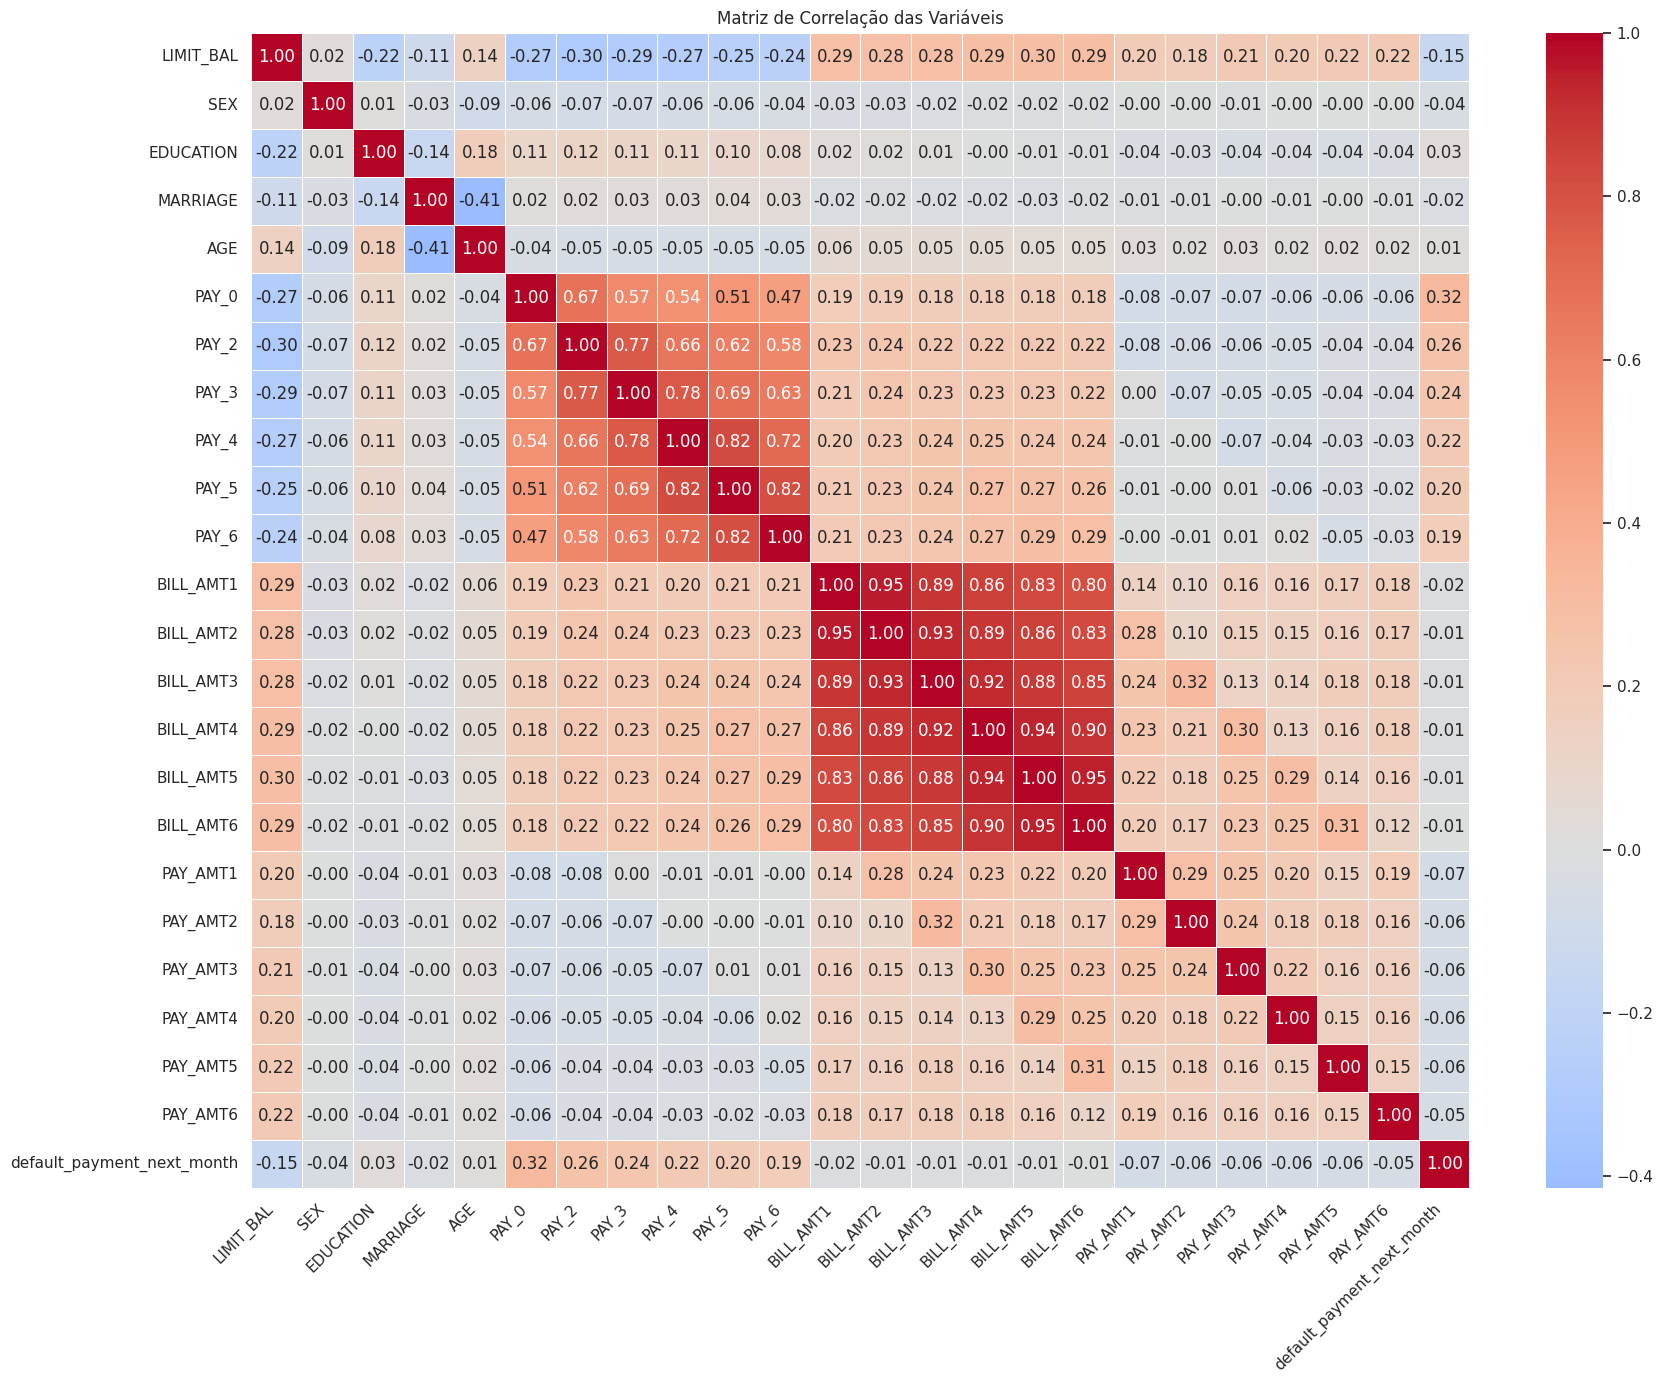

In [ ]:
# Mapa de calor
plt.figure(figsize=(18, 14))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Matriz de Correlação das Variáveis")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
# Regressão Logística
# Remove o identificador e garante que o alvo seja numérico
dados = df.drop("ID").withColumn("default_payment_next_month", F.col("default_payment_next_month").cast("double"))

# Divide os dados: 80% treinamento e 20% teste
treino, teste = dados.randomSplit([0.8, 0.2], seed=42)

print("Registros para treinamento:", treino.count())
print("Registros para teste:", teste.count())

Registros para treinamento: 24032
Registros para teste: 5968


In [ ]:
# Variáveis categóricas
categoricas = ["SEX", "EDUCATION", "MARRIAGE"]

# Transforma as categorias em texto para indexação
for coluna in categoricas:
    treino = treino.withColumn(coluna, F.col(coluna).cast("string"))
    teste = teste.withColumn(coluna, F.col(coluna).cast("string"))

# Cria os indexadores
indexadores = [
    StringIndexer(
        inputCol=coluna,
        outputCol=f"{coluna}_index",
        handleInvalid="keep"
    )
    for coluna in categoricas
]

# Codifica as categorias
codificador = OneHotEncoder(inputCols=[f"{c}_index" for c in categoricas], outputCols=[f"{c}_vec" for c in categoricas], handleInvalid="keep")

# Seleciona as variáveis numéricas
numericas = [c for c in dados.columns if c not in categoricas + ["default_payment_next_month"]]

# Junta todas as variáveis em um vetor
assembler = VectorAssembler(inputCols=numericas + [f"{c}_vec" for c in categoricas], outputCol="features")

# Padroniza as variáveis
scaler = StandardScaler(inputCol="features", outputCol="scaledFeatures", withStd=True, withMean=False)

In [ ]:
# Configuração do modelo
regressao = LogisticRegression(
    featuresCol="scaledFeatures",
    labelCol="default_payment_next_month",
    maxIter=100,
    regParam=0.01,
    elasticNetParam=0.0
)

# Cria o pipeline completo
pipeline = Pipeline(stages = indexadores + [codificador, assembler, scaler, regressao])

# Treina o modelo
modelo_logistico = pipeline.fit(treino)

print("Modelo de Regressão Logística treinado com sucesso!")

Modelo de Regressão Logística treinado com sucesso!


In [ ]:
# Realiza as previsões
previsoes_logistica = modelo_logistico.transform(teste)

# Exibe os resultados
previsoes_logistica.select(
    "default_payment_next_month",
    "prediction",
    "probability"
).show(10, truncate=False)

+--------------------------+----------+----------------------------------------+
|default_payment_next_month|prediction|probability                             |
+--------------------------+----------+----------------------------------------+
|0.0                       |0.0       |[0.5989221214069289,0.4010778785930711] |
|0.0                       |0.0       |[0.7823978429842879,0.21760215701571206]|
|0.0                       |0.0       |[0.7312710165582493,0.26872898344175067]|
|0.0                       |0.0       |[0.7425159742090086,0.2574840257909914] |
|0.0                       |0.0       |[0.9216577447607289,0.07834225523927107]|
|1.0                       |1.0       |[0.4843074640918324,0.5156925359081677] |
|0.0                       |0.0       |[0.739088466646585,0.260911533353415]   |
|0.0                       |0.0       |[0.7358846277362778,0.26411537226372217]|
|0.0                       |0.0       |[0.7142803697939467,0.2857196302060533] |
|1.0                       |

In [ ]:
# Avaliadores de classificação
avaliador = MulticlassClassificationEvaluator(labelCol="default_payment_next_month", predictionCol="prediction")

# Acurácia
acuracia = avaliador.evaluate(previsoes_logistica, {avaliador.metricName: "accuracy"})

# Precisão ponderada
precisao = avaliador.evaluate(previsoes_logistica, {avaliador.metricName: "weightedPrecision"})

# Recall ponderado
recall = avaliador.evaluate(previsoes_logistica, {avaliador.metricName: "weightedRecall"})

# F1-score ponderado
f1 = avaliador.evaluate(previsoes_logistica, {avaliador.metricName: "f1"})

# AUC-ROC
avaliador_auc = BinaryClassificationEvaluator(labelCol="default_payment_next_month", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

auc = avaliador_auc.evaluate(previsoes_logistica)

# Exibe os resultados
print("RESULTADOS - REGRESSÃO LOGÍSTICA")
print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"AUC-ROC:   {auc:.4f}")

RESULTADOS - REGRESSÃO LOGÍSTICA
Acurácia:  0.8055
Precisão:  0.7866
Recall:    0.8055
F1-score:  0.7636
AUC-ROC:   0.7059


In [ ]:
# Matriz de confusão
matriz_confusao = (previsoes_logistica.groupBy("default_payment_next_month", "prediction").count().orderBy("default_payment_next_month", "prediction"))

matriz_confusao.show()

+--------------------------+----------+-----+
|default_payment_next_month|prediction|count|
+--------------------------+----------+-----+
|                       0.0|       0.0| 4519|
|                       0.0|       1.0|  130|
|                       1.0|       0.0| 1031|
|                       1.0|       1.0|  288|
+--------------------------+----------+-----+



In [ ]:
# Árvore de Decisão
# Criar o classificador
arvore = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="default_payment_next_month",
    maxDepth=5,
    seed=42
)

# Criar pipeline de preparação e classificação
pipeline_arvore = Pipeline(
    stages=indexadores + [codificador, assembler, arvore]
)

# Treinar o modelo
modelo_arvore = pipeline_arvore.fit(treino)

print("Árvore de Decisão treinada com sucesso!")

Árvore de Decisão treinada com sucesso!


In [ ]:
# Gerar previsões
previsoes_arvore = modelo_arvore.transform(teste)

previsoes_arvore.select(
    "default_payment_next_month",
    "prediction",
    "probability"
).show(10, truncate=False)

+--------------------------+----------+----------------------------------------+
|default_payment_next_month|prediction|probability                             |
+--------------------------+----------+----------------------------------------+
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|1.0                       |1.0       |[0.2782051282051282,0.7217948717948718] |
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[0.8575121654501217,0.14248783454987834]|
|1.0                       |

In [ ]:
# Avaliar o modelo
avaliador = MulticlassClassificationEvaluator(labelCol="default_payment_next_month", predictionCol="prediction")

acuracia = avaliador.evaluate(previsoes_arvore, {avaliador.metricName: "accuracy"})

precisao = avaliador.evaluate(previsoes_arvore, {avaliador.metricName: "weightedPrecision"})

recall = avaliador.evaluate(previsoes_arvore, {avaliador.metricName: "weightedRecall"})

f1 = avaliador.evaluate(previsoes_arvore, {avaliador.metricName: "f1"})

avaliador_auc = BinaryClassificationEvaluator(labelCol="default_payment_next_month", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

auc = avaliador_auc.evaluate(previsoes_arvore)

print("RESULTADOS - ÁRVORE DE DECISÃO")
print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"AUC-ROC:   {auc:.4f}")

RESULTADOS - ÁRVORE DE DECISÃO
Acurácia:  0.8155
Precisão:  0.7967
Recall:    0.8155
F1-score:  0.7924
AUC-ROC:   0.3244


In [ ]:
# Matriz de confusão
matriz_confusao_arvore = (previsoes_arvore.groupBy("default_payment_next_month", "prediction").count().orderBy("default_payment_next_month", "prediction"))

matriz_confusao_arvore.show()

+--------------------------+----------+-----+
|default_payment_next_month|prediction|count|
+--------------------------+----------+-----+
|                       0.0|       0.0| 4414|
|                       0.0|       1.0|  235|
|                       1.0|       0.0|  866|
|                       1.0|       1.0|  453|
+--------------------------+----------+-----+



In [ ]:
# Avaliar utilizando a coluna de probabilidades
avaliador_auc_arvore = BinaryClassificationEvaluator(labelCol="default_payment_next_month", rawPredictionCol="probability", metricName="areaUnderROC")

auc_probabilidade = avaliador_auc_arvore.evaluate(previsoes_arvore)

print(f"AUC-ROC usando probability: {auc_probabilidade:.4f}")

AUC-ROC usando probability: 0.6862


In [ ]:
# Exemplos das previsões
previsoes_arvore.select("default_payment_next_month", "prediction", "rawPrediction", "probability").show(10, truncate=False)

+--------------------------+----------+----------------+----------------------------------------+
|default_payment_next_month|prediction|rawPrediction   |probability                             |
+--------------------------+----------+----------------+----------------------------------------+
|0.0                       |0.0       |[16917.0,2811.0]|[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[16917.0,2811.0]|[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[16917.0,2811.0]|[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[16917.0,2811.0]|[0.8575121654501217,0.14248783454987834]|
|0.0                       |0.0       |[16917.0,2811.0]|[0.8575121654501217,0.14248783454987834]|
|1.0                       |1.0       |[651.0,1689.0]  |[0.2782051282051282,0.7217948717948718] |
|0.0                       |0.0       |[16917.0,2811.0]|[0.8575121654501217,0.14248783454987834]|
|0.0                

In [ ]:
# Random Forest
# Criar o classificador Random Forest
floresta = RandomForestClassifier(
    featuresCol="features",
    labelCol="default_payment_next_month",
    numTrees=100,
    maxDepth=8,
    seed=42
)

# Criar o pipeline
pipeline_floresta = Pipeline(stages=indexadores + [codificador, assembler, floresta])

# Treinar o modelo
modelo_floresta = pipeline_floresta.fit(treino)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


In [ ]:
# Gerar previsões
previsoes_floresta = modelo_floresta.transform(teste)

previsoes_floresta.select("default_payment_next_month", "prediction", "probability").show(10, truncate=False)

+--------------------------+----------+----------------------------------------+
|default_payment_next_month|prediction|probability                             |
+--------------------------+----------+----------------------------------------+
|0.0                       |0.0       |[0.6348595577703884,0.3651404422296116] |
|0.0                       |0.0       |[0.7794323862724165,0.2205676137275835] |
|0.0                       |0.0       |[0.7778536500211729,0.2221463499788271] |
|0.0                       |0.0       |[0.8119780488020637,0.18802195119793624]|
|0.0                       |0.0       |[0.8019702712565223,0.19802972874347768]|
|1.0                       |1.0       |[0.4228149270447829,0.5771850729552171] |
|0.0                       |0.0       |[0.8249302650567448,0.17506973494325515]|
|0.0                       |0.0       |[0.8215173585152872,0.1784826414847128] |
|0.0                       |0.0       |[0.8086502041018823,0.19134979589811765]|
|1.0                       |

In [ ]:
# Avaliação do modelo
avaliador = MulticlassClassificationEvaluator(labelCol="default_payment_next_month", predictionCol="prediction")

acuracia = avaliador.evaluate(previsoes_floresta, {avaliador.metricName: "accuracy"})

precisao = avaliador.evaluate(previsoes_floresta, {avaliador.metricName: "weightedPrecision"})

recall = avaliador.evaluate(previsoes_floresta, {avaliador.metricName: "weightedRecall"})

f1 = avaliador.evaluate(previsoes_floresta, {avaliador.metricName: "f1"})

avaliador_auc = BinaryClassificationEvaluator(labelCol="default_payment_next_month", rawPredictionCol="probability", metricName="areaUnderROC")

auc = avaliador_auc.evaluate(previsoes_floresta)

print("RESULTADOS - RANDOM FOREST")
print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"AUC-ROC:   {auc:.4f}")

RESULTADOS - RANDOM FOREST
Acurácia:  0.8133
Precisão:  0.7937
Recall:    0.8133
F1-score:  0.7900
AUC-ROC:   0.7715


In [ ]:
# Matriz de confusão
matriz_confusao_floresta = (previsoes_floresta.groupBy("default_payment_next_month", "prediction").count().orderBy("default_payment_next_month", "prediction"))

matriz_confusao_floresta.show()

+--------------------------+----------+-----+
|default_payment_next_month|prediction|count|
+--------------------------+----------+-----+
|                       0.0|       0.0| 4407|
|                       0.0|       1.0|  242|
|                       1.0|       0.0|  872|
|                       1.0|       1.0|  447|
+--------------------------+----------+-----+



In [ ]:
# Salvamento do arquivo
df.coalesce(1).write.mode("overwrite").option("header", True).option("encoding", "UTF-8").csv('/content/drive/MyDrive/Projeto Semantix/output/default_of_credit_card_clients_tratado.csv')

print("Arquivo salvo com sucesso!")

Arquivo salvo com sucesso!


In [ ]:
df6 = spark.read.csv("/content/drive/MyDrive/Projeto Semantix/output/default_of_credit_card_clients_tratado.csv", header=True, inferSchema=True)

df6.show(3)
df6.printSchema()

+---+---------+---+---------+--------+---+-----+-----+-----+-----+-----+-----+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+--------------------------+
| ID|LIMIT_BAL|SEX|EDUCATION|MARRIAGE|AGE|PAY_0|PAY_2|PAY_3|PAY_4|PAY_5|PAY_6|BILL_AMT1|BILL_AMT2|BILL_AMT3|BILL_AMT4|BILL_AMT5|BILL_AMT6|PAY_AMT1|PAY_AMT2|PAY_AMT3|PAY_AMT4|PAY_AMT5|PAY_AMT6|default_payment_next_month|
+---+---------+---+---------+--------+---+-----+-----+-----+-----+-----+-----+---------+---------+---------+---------+---------+---------+--------+--------+--------+--------+--------+--------+--------------------------+
|  1|    20000|  2|        2|       1| 24|    2|    2|   -1|   -1|   -2|   -2|     3913|     3102|      689|        0|        0|        0|       0|     689|       0|       0|       0|       0|                         1|
|  2|   120000|  2|        2|       2| 26|   -1|    2|    0|    0|    0|    2|     2682|     1725|     2682|     3272|  

In [ ]:
# Finalização da sessão spark
spark.stop()